<div dir="rtl">

# تمرين 4.1: معيار الباب الخلفي

**برنامج التجارب واختبارات A/B والاستدلال السببي**، اليوم الرابع

**الخطوات:**
1. من قائمة File اختر Save a copy in Drive، واعمل على النسخة التي تُفتح.
2. شغّل الخلايا بالترتيب، ثم اكتب حلك في الخلية المخصصة.
3. اضغط Share، واجعل General access على Anyone with the link بصلاحية Viewer، ثم اضغط Copy link.
4. الصق الرابط في ملف التقييم الخاص بمجموعتك، في عمود «تمرين 4.1».

</div>

<div dir="rtl">

## الإعداد

شغّل الخلية التالية أولًا.

</div>

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import html
from IPython.display import HTML, display

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler
from matplotlib import ft2font
from scipy import stats

# الإصدارات الحديثة من matplotlib تعرض العربية مباشرة، والقديمة تحتاج مكتبتين صغيرتين
NATIVE_ARABIC = hasattr(ft2font, "__libraqm_version__")
if not NATIVE_ARABIC:
    try:
        import arabic_reshaper
        from bidi.algorithm import get_display
    except ImportError:
        import subprocess
        import sys
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "arabic-reshaper", "python-bidi"], check=True)
        import arabic_reshaper
        from bidi.algorithm import get_display

rng = np.random.default_rng(2026)

# ألوان البرنامج: A تركوازي، وB برتقالي، والقيمة الحقيقية كحلي، والطريقة الساذجة رمادي
TEAL, ORANGE, NAVY, GRAY = "#0E7490", "#E58A1F", "#0F2A3F", "#A9B4BC"
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "figure.dpi": 110,
    "axes.prop_cycle": cycler(color=[TEAL, ORANGE, NAVY, GRAY]),
    "axes.edgecolor": "#56656F", "axes.labelcolor": NAVY, "text.color": NAVY,
    "xtick.color": "#3D4F5C", "ytick.color": "#3D4F5C",
    "axes.grid": True, "grid.color": "#D8E1E7", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "font.size": 11,
    "legend.frameon": False,
})
pd.set_option("display.precision", 4)


def ar(text):
    """يجهز النص العربي ليظهر بالشكل والاتجاه الصحيحين داخل الرسوم."""
    text = str(text)
    return text if NATIVE_ARABIC else get_display(arabic_reshaper.reshape(text))


def say(*parts, sep=" "):
    """يطبع نصًا عربيًا من اليمين إلى اليسار."""
    text = html.escape(sep.join(str(p) for p in parts))
    display(HTML(f'<div dir="rtl" style="white-space: pre-wrap; line-height: 1.7;">{text}</div>'))


import networkx as nx
import statsmodels.formula.api as smf
from IPython.display import Markdown, display


def tidy(fit, terms=None):
    """جدول مختصر لنتيجة الانحدار."""
    ci = fit.conf_int()
    out = pd.DataFrame({"المعامل": fit.params, "SE": fit.bse, "أدنى 95%": ci[0], "أعلى 95%": ci[1], "p": fit.pvalues})
    return out.loc[terms] if terms else out


def draw_dag(ax, edges, pos, title, highlight=None, unobserved=()):
    """يرسم رسمًا سببيًا: البرتقالي هو المتغير المهم في المثال، والرمادي متغير لا نقيسه."""
    g = nx.DiGraph(edges)
    colors = ["#FCEBD7" if v == highlight else ("#E4E9ED" if v in unobserved else "#E0F0F4") for v in g.nodes]
    nx.draw_networkx(g, pos=pos, ax=ax, labels={v: ar(v) for v in g.nodes}, node_color=colors, node_size=4600,
                     font_size=9, font_color=NAVY, edgecolors=NAVY, edge_color=NAVY, arrowsize=16, width=1.2)
    ax.set_title(ar(title), fontsize=10.5)
    ax.axis("off")
    ax.margins(0.25)


say("الإعداد جاهز")

<div dir="rtl">

## الأدوات الجاهزة

هذه الدوال والبيانات من دفتر اليوم، ويحتاجها التمرين. شغّلها كما هي.

</div>

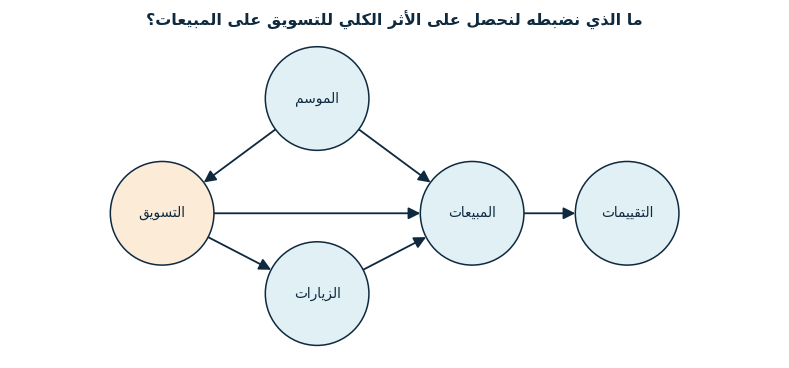

In [ ]:
fig, ax = plt.subplots(figsize=(9, 3.8))
draw_dag(ax, [("الموسم", "التسويق"), ("الموسم", "المبيعات"), ("التسويق", "الزيارات"), ("الزيارات", "المبيعات"),
              ("التسويق", "المبيعات"), ("المبيعات", "التقييمات")],
         {"الموسم": (1, 1), "التسويق": (0, 0), "الزيارات": (1, -0.7), "المبيعات": (2, 0), "التقييمات": (3, 0)},
         "ما الذي نضبطه لنحصل على الأثر الكلي للتسويق على المبيعات؟", highlight="التسويق")
plt.show()

<div dir="rtl">

## المطلوب

**قبل تشغيل خلية التحقق:** هل تعطي كل مجموعة ضبط الأثر الكلي الصحيح للتسويق على المبيعات؟ ولماذا؟

1. بدون ضبط
2. الموسم فقط
3. الموسم والزيارات
4. الموسم والتقييمات

</div>

<div dir="rtl">

| المجموعة | صحيحة؟ | السبب |
|---|---|---|
| بدون ضبط | لا | لأننا لا نأخذ المتغييرات المشتركة في الاعتبار |
| الموسم فقط | نعم |  متغير مربك، الموسم يؤثر على التسويق والنتيجة |
| الموسم والزيارات | لا | الزيارات هي الوسيط |
| الموسم والتقييمات | لا | التقييمات هي النتيجة |

</div>

<div dir="rtl">

## تحقق من إجابتك

بعد أن تكتب إجابتك، شغّل الخلية التالية وقارن النتائج بما توقعت.

</div>

In [ ]:
r = np.random.default_rng(4)
n = 20_000
season = r.normal(size=n)
marketing = 1.0 * season + r.normal(size=n)
visits = 1.2 * marketing + r.normal(size=n)
sales = 0.5 * marketing + 1.0 * visits + 2.0 * season + r.normal(size=n)
reviews = 0.8 * sales + r.normal(size=n)
mk = pd.DataFrame({"season": season, "marketing": marketing, "visits": visits, "sales": sales, "reviews": reviews})

adjustment_sets = {"بدون ضبط": "", "الموسم فقط": " + season", "الموسم والزيارات": " + season + visits",
                   "الموسم والتقييمات": " + season + reviews"}
estimates = {k: smf.ols("sales ~ marketing" + v, mk).fit().params["marketing"] for k, v in adjustment_sets.items()}
say("الأثر الكلي الحقيقي = 0.5 + 1.2 × 1.0 = 1.7")
pd.Series(estimates, name="معامل التسويق").round(2).to_frame()

,معامل التسويق
بدون ضبط,2.70
الموسم فقط,1.69
الموسم والزيارات,0.50
الموسم والتقييمات,0.74


**التحليل:**
الضبط على الموسم فقط أعطى 1.69، وهو قريب من الأثر الكلي الحقيقي 1.7، بينما ضبط الزيارات (الوسيط) أعطى الأثر المباشر فقط 0.5، وضبط التقييمات أفسد التقدير فأعطى 0.74، وعدم الضبط أعطى 2.70 بسبب تحيّز الموسم




<div dir="rtl">

## التسليم

انتهيت؟ اضغط Share، ثم Copy link، والصق الرابط في ملف التقييم في عمود «تمرين 4.1».

</div>